<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">

  <h1 style="color: #c25719; border-bottom: 2px solid #c25719; padding-bottom: 8px; margin-top: 0;">
    LNDb: Lung Nodule Database
  </h1>

  <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
    A dataset built after LIDC IDRI
  </h3>

  <p>
   LNDb was developed as an external dataset that complements LIDC IDRI. While LIDC IDRI was built by seven institutions, LNDb is smaller and comes from a single one, the Centro Hospitalar e Universitário de São João (CHUSJ) in Porto.
  </p>
  <p>
   LNDb contains 294 CT scans, about a quarter of LIDC IDRI, and it was read differently: each radiologist read a scan once, with no consensus or review between radiologists (a single blind reading). The rating habits of each radiologist are therefore more visible, but, unlike in LIDC IDRI, the five radiologists keep the same identity across the whole dataset, R1 to R5.
  </p>
  <p>
   Acquisition is far more homogeneous in LNDb (one hospital, three Siemens scanner models), which makes it closer to a single clinical setting.
  </p>

  <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
    Reading the scans
  </h3>

  <p>
    The dataset ships helper scripts. <strong>'utils.py'</strong> reads the MetaImage <strong>.mhd/.raw</strong> files, the format of both the CT scans and the radiologists' masks, and gives us:
  </p>
  <ol style="padding-left: 20px; margin-bottom: 20px;">
    <li style="margin-bottom: 8px;">the 3D CT images and the nodule masks;</li>
    <li style="margin-bottom: 8px;">their metadata: the voxel spacing, the origin and the orientation matrix of the CT.</li>
  </ol>
  <p>
    We wrote <strong>read_nods_in_scan</strong>, which reads one scan and its findings and converts their coordinates from millimetres to voxel indices with the origin, spacing and orientation of that scan, and does the same for the masks. With it we can look at any finding and its mask.
  </p>
</div>

In [1]:
import sys
from pathlib import Path
import ast
import math
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")

root_path = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
if str(root_path) not in sys.path: sys.path.append(str(root_path))

from src.mass_detect.scripts.config import LNDB_NODULES_FILE
from src.mass_detect.scripts.schema import SCHEMA, equivalent_diameter
from src.mass_detect.lndb_utils import utils
from src.mass_detect.scripts.lndb_exploration_utils import find_file, read_nods_in_scan

BLUE, ORANGE, GREY, OLIVE = "blue", "orange", "grey", "olive"
plt.rcParams.update({
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": GREY,
    "axes.grid": True,
    "axes.grid.axis": "y",
    "axes.axisbelow": True,
    "grid.color": "w",
    "grid.linewidth": 0.8,
    "axes.titlesize": 12,
    "axes.titleweight": "normal",
    "figure.dpi": 110,
})

train_nodules = pd.read_csv(find_file("trainNodules.csv"))
ct_scan_id = 1
scan, spacing, origin, nods_scan = read_nods_in_scan(ct_scan_id, train_nodules)

print(f"The CT Scan {ct_scan_id} has...\n  -> dimensions {scan.shape}\n  -> origin {origin}\n  -> spacing {spacing}\n")
print(f"For this scan, we have {len(nods_scan)} findings:")
print(nods_scan[['LNDbID', 'RadID', 'FindingID', 'x_img', 'y_img', 'z_img']])

The CT Scan 1 has...
  -> dimensions (328, 512, 512)
  -> origin (-158.1962890625, -309.1962890625, -297.5)
  -> spacing (0.607421875, 0.607421875, 1.0)

For this scan, we have 4 findings:
   LNDbID  RadID  FindingID  x_img  y_img  z_img
0       1      1          1  187.0  313.0  260.0
1       1      1          2  303.0  300.0  252.0
2       1      2          1  188.0  314.0  260.0
3       1      3          1  188.0  312.0  260.0


<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <p>
    The scan has 328 slices of 512 x 512 pixels. Its voxel spacing, (0.607, 0.607, 1.0) mm, shows that the volume <strong>is not isotropic</strong>: the pixels are finer than the distance between slices. This matters for every feature that compares neighbouring voxels, and it is why the patches are resampled later.
  </p>
  <div style="background-color: #c25719; padding: 2px 10px; border-radius: 0px; margin: 0px -10px;">
    <strong style="color: #1967d2;">Note:</strong> an isotropic volume has the same spacing in every direction (x, y, z), so each voxel is a perfect cube.
  </div>
  <p>
    The origin is the world coordinate of the corner of the volume, which is needed to convert the coordinates of the findings.
  </p>
  <p>
    To confirm the conversion, we show the slice where each finding was annotated, with a red <strong>X</strong> at its position, next to the same slice without the mark.
  </p>
</div>

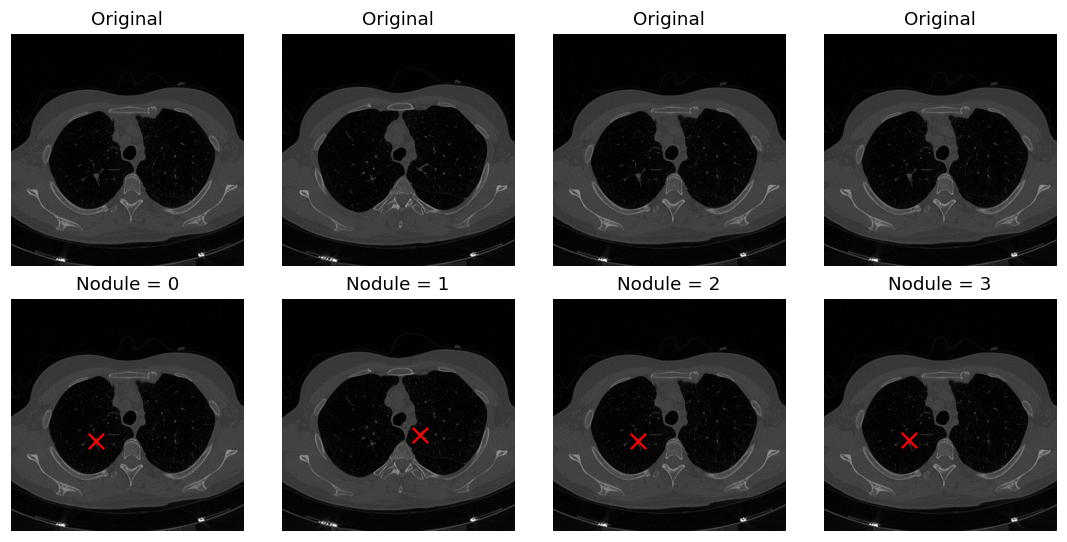

In [2]:
fig, axes = plt.subplots(2, 4, figsize=(10, 5))
for i in range(len(nods_scan)):
    axes[0][i].imshow(scan[int(nods_scan['z_img'].iloc[i])], cmap='gray')
    axes[0][i].set_title(f"Original")
    axes[0][i].axis("off")  # Hides x and y tick marks
    axes[1][i].imshow(scan[int(nods_scan['z_img'].iloc[i])], cmap='gray')
    axes[1][i].set_title(f"Nodule = {i}")
    axes[1][i].scatter(nods_scan['x_img'].iloc[i], nods_scan['y_img'].iloc[i], c='red', marker='x', s=100)  # marca a posição do nódulo
    axes[1][i].axis("off")
plt.tight_layout()
plt.show()

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <p>
    The annotated positions do fall on a nodule. In this scan, findings 0, 2 and 3 are the same nodule, marked by three different radiologists, as their positions and the closer look below confirm. <strong>'utils.py'</strong> extracts a small cube around a point (80 voxels per side by default), which gives a centred view of each finding and its mask.
  </p>
</div>

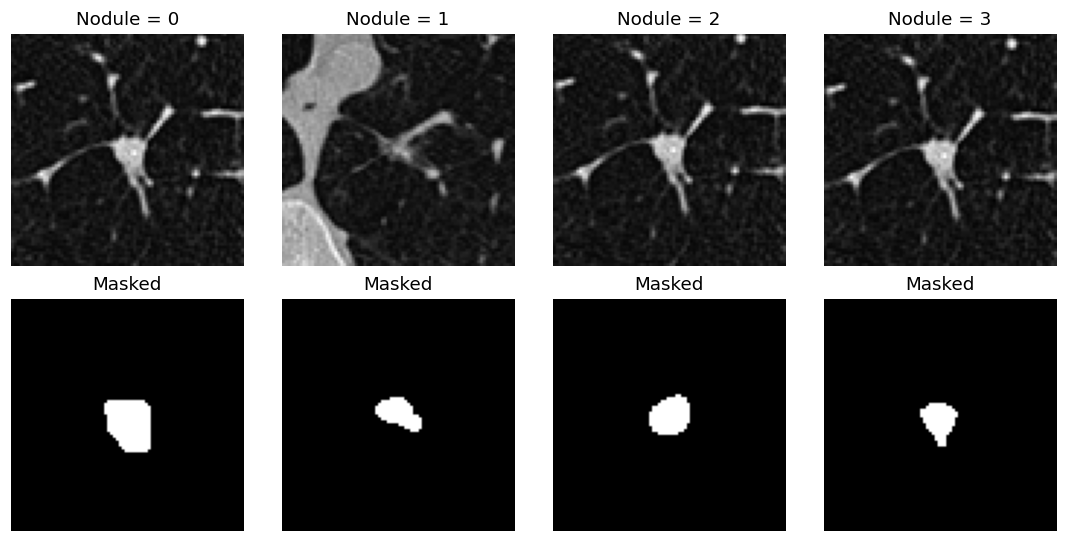

In [3]:
fig, axes = plt.subplots(2, 4, figsize=(10, 5))
for i in range(len(nods_scan)):
    cube = utils.extractCube(scan, spacing, (nods_scan['x_img'].iloc[i], nods_scan['y_img'].iloc[i], nods_scan['z_img'].iloc[i]))
    mask_cube = utils.extractCube(nods_scan['mask'].iloc[i], spacing, (nods_scan['x_img'].iloc[i], nods_scan['y_img'].iloc[i], nods_scan['z_img'].iloc[i]))
    axes[0][i].imshow(cube[cube.shape[0]//2], cmap='gray')
    axes[0][i].set_title(f"Nodule = {i}")
    axes[0][i].axis("off")  # Hides x and y tick marks
    axes[1][i].imshow(mask_cube[mask_cube.shape[0]//2], cmap = 'gray')
    axes[1][i].set_title(f"Masked")
    axes[1][i].axis("off")

plt.tight_layout()
plt.show() 

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <p>
    The repeated findings come from the fact that <strong>'trainNodules.csv'</strong> has one row per reading: one radiologist marking one finding. A nodule seen by three radiologists has three rows, and their masks differ even though the nodule is the same. Deciding how to combine the readings of one nodule is therefore a central step of the preparation.
  </p>
  <p>
    <strong>'chars_trainNodules.csv'</strong> has the same rows in the same order and holds the subjective characteristics of each reading (calcification, internal structure, malignancy and others), while <strong>'trainNodules.csv'</strong> holds the position, the nodule or non nodule call, the volume and the texture. We join the two by row position.
  </p>
  <p>
    The join must be by position and not by 'RadID'. In <strong>'trainNodules.csv'</strong> 'RadID' is the number of the reader inside the scan (1, 2 or 3), while in <strong>'chars_trainNodules.csv'</strong> it is the global identity of the radiologist (1 to 5). We keep the global one as 'RadID_real'.
  </p>
</div>

In [4]:
chars_train_nodules = pd.read_csv(find_file('chars_trainNodules.csv'))
train = pd.read_csv(find_file('trainNodules.csv'))

# Positional join: only valid if lines correspond to the same finding
assert len(train) == len(chars_train_nodules)
assert (train[['LNDbID', 'FindingID']].values == chars_train_nodules[['LNDbID', 'FindingID']].values).all()

combined_df = pd.concat([train, chars_train_nodules.drop(columns=['LNDbID', 'FindingID']).rename(columns={'RadID': 'RadID_real'})],axis=1,)
combined_df['RadID_real'] = combined_df['RadID_real'].astype(int)

# 'outer' keeps all entries, 'inner' keeps only nodules present in both.
#combined_df = pd.merge(train, char_train, on=['LNDbID', 'RadID', 'FindingID'], how="outer")

print(combined_df.shape)
print(" | ".join(combined_df.columns))

(1527, 18)
LNDbID | RadID | FindingID | x | y | z | Nodule | Volume | Text | RadID_real | calcification | internalStructure | lobulation | malignancy | margin | sphericity | spiculation | subtlety


<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <p>
    The meaning of each column of the joined table:
  </p>
  <ul style="padding-left: 20px; margin-bottom: 20px;">
    <li style="margin-bottom: 8px;">Each line is a finding <strong style="color: #c25719;">FindingID</strong> marked by a radiologist <strong style="color: #c25719;">RadID_real</strong> in a scan <strong style="color: #c25719;">LNDbID</strong>.</li>
    <li style="margin-bottom: 8px;"><strong style="color: #c25719;">x</strong>, <strong style="color: #c25719;">y</strong> and <strong style="color: #c25719;">z</strong> are the coordinates of the finding, in millimetres.</li>
    <li style="margin-bottom: 8px;"><strong style="color: #c25719;">Nodule</strong> is 1 if the finding is a nodule and 0 if it is not.</li>
    <li style="margin-bottom: 8px;"><strong style="color: #c25719;">Volume</strong> is the volume of the annotated lesion, in cubic millimetres.</li>
    <li style="margin-bottom: 8px;"><strong style="color: #c25719;">Text</strong> is the texture of the nodule, from ground glass to solid.</li>
    <li style="margin-bottom: 8px;"><strong style="color: #c25719;">Calcification</strong> describes calcium deposits inside the nodule, which can be concentric rings, off centre deposits or tiny scattered specks.</li>
    <li style="margin-bottom: 8px;"><strong style="color: #c25719;">Internal Structure</strong> describes what the inside of the nodule is made of: soft tissue, fluid, fat or air. Fat strongly favours a benign hamartoma, while a cavity calls for careful evaluation.</li>
    <li style="margin-bottom: 8px;"><strong style="color: #c25719;">Lobulation</strong> describes a wavy outer contour instead of a smooth one, caused by parts of the nodule growing at different rates.</li>
    <li style="margin-bottom: 8px;"><strong style="color: #c25719;">Malignancy</strong> rates from 1 to 5 how likely the radiologist thinks the nodule is to be cancer.</li>
    <li style="margin-bottom: 8px;"><strong style="color: #c25719;">Margin</strong> describes the border between the nodule and the lung, from sharp and well defined to poorly defined.</li>
    <li style="margin-bottom: 8px;"><strong style="color: #c25719;">Sphericity</strong> describes how close the nodule is to a sphere, as opposed to an elongated or flat shape.</li>
    <li style="margin-bottom: 8px;"><strong style="color: #c25719;">Spiculation</strong> describes strands radiating from the edge of the nodule into the lung, a starburst appearance.</li>
    <li style="margin-bottom: 8px;"><strong style="color: #c25719;">Subtlety</strong> describes how easy the nodule is to tell apart from the structures around it.</li>
  </ul>
  <p>
    A third file, <strong>'allNods.csv'</strong>, groups the findings by nodule and is centred on the text reports. Its <strong>'Lobe'</strong> column says in which lobe each nodule lies. Its 'FindingID', however, does not follow the same merge as <strong>'trainNodules_gt.csv'</strong>, so the lobe is matched by position when the nodule table is built below.
  </p>
</div>

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <h1 style="color: #c25719; border-bottom: 2px solid #c25719; padding-bottom: 8px; margin-top: 0;">
    One Row per Nodule
  </h1>
  <p>
    <strong>'trainNodules_gt.csv'</strong> merges the readings of the same lesion into one finding. For each finding it lists the radiologists who marked it ('RadID') and the number each of them gave it ('RadFindingID'). We expand those lists, attach to each reading its rating through the row position join, and summarise the ratings of each finding.
  </p>
  <ul style="padding-left: 20px; margin-bottom: 20px;">
    <li style="margin-bottom: 8px;">A rating of 0 means that the field was not filled in, so it becomes a missing value and not a benign rating.</li>
    <li style="margin-bottom: 8px;">The label is the mean of the remaining ratings. It is rounded half up later, in notebook 03 (notebook 00 explains why).</li>
    <li style="margin-bottom: 8px;">We also keep the lowest and the highest rating and the number of readers, to measure agreement and to weight readings later.</li>
  </ul>
</div>

In [5]:
# The two reading level files must have the same rows in the same order
assert len(train_nodules) == len(chars_train_nodules)
same_ct = train_nodules["LNDbID"].to_numpy() == chars_train_nodules["LNDbID"].astype(int).to_numpy()
same_finding = train_nodules["FindingID"].to_numpy() == chars_train_nodules["FindingID"].astype(int).to_numpy()
assert same_ct.all() and same_finding.all()

# Inside each CT, a local radiologist number must always match the same global one
pairs = pd.DataFrame({"ct": train_nodules["LNDbID"],
                      "local_rad": train_nodules["RadID"],
                      "global_rad": chars_train_nodules["RadID"].astype(int)}).drop_duplicates()
assert not pairs.duplicated(["ct", "local_rad"]).any()
assert not pairs.duplicated(["ct", "global_rad"]).any()

# One row per reading, with the radiologist and the malignancy rating (0 means not filled in)
readings = train_nodules[["LNDbID", "RadID", "FindingID"]].copy()
readings["reader"] = "R" + chars_train_nodules["RadID"].astype(int).astype(str)
readings["malignancy"] = chars_train_nodules["malignancy"].replace(0, np.nan).to_numpy()
readings.head(10)

,LNDbID,RadID,FindingID,reader,malignancy
0,1,1,1,R1,2.0
1,1,1,2,R1,2.0
2,1,2,1,R2,2.0
3,1,3,1,R3,2.0
4,2,1,1,R1,1.0
5,2,1,2,R1,1.0
6,2,1,3,R1,3.0
7,2,1,4,R1,2.0
8,2,1,5,R1,2.0
9,2,2,1,R2,1.0


In [6]:
train_nodules_gt = pd.read_csv(find_file("trainNodules_gt.csv"))

# Expand the comma separated lists, for example RadID "1,2,3" and RadFindingID "1,1,3"
expanded = []
for finding in train_nodules_gt.itertuples():
    rad_ids = str(finding.RadID).split(",")
    reading_ids = str(finding.RadFindingID).split(",")
    for rad_id, reading_id in zip(rad_ids, reading_ids):
        expanded.append({"LNDbID": finding.LNDbID,
                         "merged_finding": finding.FindingID,
                         "RadID": int(rad_id),
                         "FindingID": int(reading_id)})
expanded = pd.DataFrame(expanded)

# Every reading must find its row in the readings table, and none may be left over
expanded = expanded.merge(readings, on=["LNDbID", "RadID", "FindingID"], how="left", validate="many_to_one")
assert len(expanded) == len(train_nodules)
assert expanded["malignancy"].notna().sum() == chars_train_nodules["malignancy"].gt(0).sum()
expanded["nodule_uid"] = expanded["LNDbID"].map("LNDb-{:04d}".format) + "_" + expanded["merged_finding"].astype(str)

# One row per unique finding, with the statistics of its ratings
grouped = expanded.groupby(["LNDbID", "merged_finding"])
ratings = grouped["malignancy"].agg(mal_mean="mean", mal_min="min", mal_max="max", n_rated="count")
ratings["n_readings"] = grouped.size()
ratings.head(10)

mal_mean  mal_min  mal_max  n_rated  n_readings
LNDbID merged_finding                                                 
1      1                    2.0      2.0      2.0        3           3
       2                    2.0      2.0      2.0        1           1
2      1                    1.0      1.0      1.0        3           3
       2                    1.0      1.0      1.0        2           2
       3                    2.5      2.0      3.0        2           2
       4                    2.0      2.0      2.0        1           1
       5                    2.0      2.0      2.0        1           1
       6                    1.0      1.0      1.0        1           1
       7                    2.0      2.0      2.0        1           1
       8                    1.0      1.0      1.0        1           1

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <p>
    Two details need care:
  </p>
  <ul style="padding-left: 20px; margin-bottom: 20px;">
    <li style="margin-bottom: 8px;"><strong>Volumes that are not measurements.</strong> When a radiologist only marked the centre of a finding, LNDb stores the volume of a 3 mm sphere. That affects all the non nodules and the nodules under 3 mm. We flag them with 'volume_is_placeholder' and leave their volume and diameter empty, so that nobody mistakes them for real sizes.</li>
    <li style="margin-bottom: 8px;"><strong>The lobe.</strong> <strong>'allNods.csv'</strong> has the lobe, but it was merged with a different procedure, so its 'FindingID' is not the same as in <strong>'trainNodules_gt.csv'</strong>. We therefore match the lobe by position: for each finding we take the closest annotation of the same CT, and accept it if it is within 3 mm. The cell after the table checks how often the plain 'FindingID' would have been wrong.</li>
  </ul>
</div>

In [7]:
LOBE_TOLERANCE_MM = 3.0

all_nods = pd.read_csv(find_file("allNods.csv"))
all_nods = all_nods[all_nods["Where"].str.contains("RadAnnotation", na=False)]   # skip nodules only in reports

lobe = pd.Series(np.nan, index=train_nodules_gt.index)
for ct_id, finding_rows in train_nodules_gt.groupby("LNDbID"):
    candidates = all_nods[all_nods["LNDbID"] == ct_id]
    if candidates.empty:
        continue
    for index, finding in finding_rows.iterrows():
        offsets = candidates[["x", "y", "z"]].to_numpy() - np.array([finding["x"], finding["y"], finding["z"]])
        distances = np.linalg.norm(offsets, axis=1)
        if distances.min() <= LOBE_TOLERANCE_MM:
            lobe[index] = float(candidates["Lobe"].iloc[distances.argmin()])

In [8]:
# Scanner information per CT. Some columns hold lists written as text, for example "['Br64f', '3']".
acquisition = pd.read_csv(find_file("LNDbAcqParams.csv"))

def first_item(text): # Returns the first element when the text is a list, otherwise the text itself.
    if isinstance(text, str) and text.startswith("["):
        return ast.literal_eval(text)[0]
    return text

scanner = pd.DataFrame({
    "LNDbID": acquisition["LNDbID"],
    "slice_thickness_mm": acquisition["SliceThickness"],
    "pixel_spacing_mm": acquisition["PixelSpacing"].map(lambda text: float(first_item(text))),
    "manufacturer": acquisition["Manufacturer"].str.upper().str.split().str[0],
    "model": acquisition["ManufacturerModelName"],
    "kernel": acquisition["ConvolutionKernel"].map(first_item),
    "kvp": acquisition["KVP"],
})

In [9]:
PLACEHOLDER_VOLUME = 4 * math.pi * 1.5 ** 3 / 3    # volume of a sphere with 3 mm of diameter

lndb = train_nodules_gt.merge(ratings, left_on=["LNDbID", "FindingID"], right_index=True, how="left")
lndb["lobe"] = lobe

is_placeholder = np.isclose(lndb["Volume"], PLACEHOLDER_VOLUME)
lndb["volume_is_placeholder"] = is_placeholder
lndb["volume_mm3"] = lndb["Volume"].where(~is_placeholder)       # empty when it is not a measurement
lndb["diameter_mm"] = equivalent_diameter(lndb["volume_mm3"])

lndb["dataset"] = "LNDb"
lndb["scan_id"] = lndb["LNDbID"].map("LNDb-{:04d}".format)
lndb["patient_id"] = lndb["scan_id"]
lndb["nodule_uid"] = lndb["scan_id"] + "_" + lndb["FindingID"].astype(str)
lndb["is_nodule"] = lndb["Nodule"].astype(int)
lndb["reclustered"] = False
lndb["oversized_group"] = False
lndb = lndb.rename(columns={"x": "x_mm", "y": "y_mm", "z": "z_mm"})
lndb = lndb.merge(scanner, on="LNDbID", how="left", validate="many_to_one")
for column in ("vox_row", "vox_col", "vox_slice"):
    lndb[column] = np.nan
lndb = lndb.reindex(columns=SCHEMA)   # annotation_ids exists only in LIDC, so it stays empty here

rated = lndb[(lndb["is_nodule"] == 1) & lndb["mal_mean"].notna()]
print(f"{len(lndb)} findings in {lndb['scan_id'].nunique()} CTs: "
      f"{lndb['is_nodule'].sum()} nodules and {(lndb['is_nodule'] == 0).sum()} non nodules")
print(f"{len(rated)} nodules have a rating, {(rated['n_rated'] > 1).sum()} of them by more than one radiologist")
print(f"Placeholder volumes: {is_placeholder.sum()} ({lndb.loc[lndb['is_nodule'] == 1, 'volume_is_placeholder'].sum()} of them nodules)")
print(f"Findings without a lobe: {lndb['lobe'].isna().sum()}")

# Why the lobe is matched by position: the same FindingID points to different places in the two files
same_id = train_nodules_gt.merge(all_nods, on=["LNDbID", "FindingID"], suffixes=("_gt", "_all"))
shift = np.linalg.norm(same_id[["x_gt", "y_gt", "z_gt"]].to_numpy() - same_id[["x_all", "y_all", "z_all"]].to_numpy(), axis=1)
print(f"Same FindingID but more than 1 mm apart: {(shift > 1).sum()} of {len(same_id)} findings")

1219 findings in 229 CTs: 768 nodules and 451 non nodules
765 nodules have a rating, 221 of them by more than one radiologist
Placeholder volumes: 594 (143 of them nodules)
Findings without a lobe: 6
Same FindingID but more than 1 mm apart: 90 of 1152 findings


In [10]:
lndb.to_csv(LNDB_NODULES_FILE, index=False)
print("saved", lndb.shape, "->", LNDB_NODULES_FILE.name)

saved (1219, 29) -> lndb_nodules.csv


<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
    Nodules and non nodules
  </h3>
  <p>
    The files mix nodules and non nodules, and readings and findings. Before looking at the nodules, we count what each level contains and how many examples are left for a malignancy model that needs a radiologist mask.
  </p>
</div>

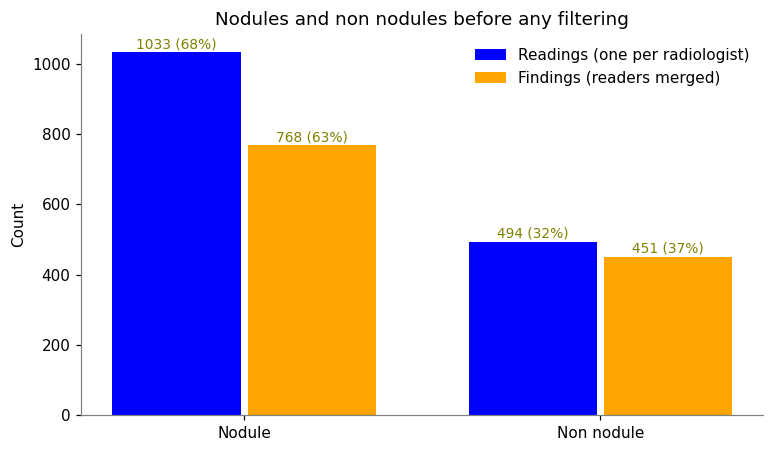

CT scans in LNDb: 294, of which 236 in the training set
Training scans with at least one finding: 229 | with at least one nodule: 212
readers per scan
1     59
2    110
3     67
Non nodules marked by a single reader: 408


,readings,nodules or findings,patients
all readings,1527,1219,229
readings of nodules,1033,768,212
with a rating,1030,765,212
with a radiologist mask (3 mm or more),885,622,204


In [11]:
# Two levels: readings (one radiologist and one finding) and findings (the readings of one lesion merged)
per_reading = train_nodules["Nodule"].value_counts().reindex([1, 0])
per_finding = train_nodules_gt["Nodule"].value_counts().reindex([1, 0])
x, width = np.arange(2), 0.36
fig, ax = plt.subplots(figsize=(8, 4.5))
for offset, series, color, label in [(-width / 2 - 0.01, per_reading, BLUE, "Readings (one per radiologist)"),
                                     (width / 2 + 0.01, per_finding, ORANGE, "Findings (readers merged)")]:
    bars = ax.bar(x + offset, series.values, width, color=color, label=label)
    for bar, n in zip(bars, series.values):
        ax.text(bar.get_x() + bar.get_width() / 2, n + 12, f"{n} ({n / series.sum():.0%})", ha="center", fontsize=9, color=OLIVE)
ax.set_xticks(x, ["Nodule", "Non nodule"])
ax.set_ylabel("Count")
ax.set_title("Nodules and non nodules before any filtering")
ax.legend(frameon=False)
plt.show()

all_scans = pd.read_csv(find_file("LNDbAcqParams.csv"))["LNDbID"]
train_cts = pd.read_csv(find_file("trainCTs.csv"))
print(f"CT scans in LNDb: {len(all_scans)}, of which {len(train_cts)} in the training set")
print("Training scans with at least one finding:", lndb["scan_id"].nunique(), "| with at least one nodule:", lndb.loc[lndb["is_nodule"] == 1, "scan_id"].nunique())
print(train_cts["RadN"].value_counts().sort_index().rename_axis("readers per scan").rename("scans").to_string())
print("Non nodules marked by a single reader:",
      (train_nodules_gt.loc[train_nodules_gt["Nodule"] == 0, "RadID"].astype(str).str.count(",") == 0).sum())

# From readings to the nodules a malignancy model can use
steps = expanded.merge(lndb[["nodule_uid", "patient_id", "is_nodule", "volume_is_placeholder"]], on="nodule_uid")
keep = pd.Series(True, index=steps.index)
funnel = {}
for name, rule in [("all readings", keep),
                   ("readings of nodules", steps["is_nodule"] == 1),
                   ("with a rating", steps["malignancy"].notna()),
                   ("with a radiologist mask (3 mm or more)", ~steps["volume_is_placeholder"].astype(bool))]:
    keep = keep & rule
    funnel[name] = {"readings": int(keep.sum()), "nodules or findings": steps.loc[keep, "nodule_uid"].nunique(),
                    "patients": steps.loc[keep, "patient_id"].nunique()}
pd.DataFrame(funnel).T

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <p>
    The training set has 236 of the 294 CT scans; the other 58 form the challenge test set, which this report does not use. 229 training scans have at least one finding and 212 at least one nodule. Most scans were read by more than one radiologist: 59 by one, 110 by two and 67 by three.
  </p>
  <p>
    There are 1527 readings: 1033 of nodules (68%) and 494 of non nodules (32%). After merging the readers there are 1219 findings, 768 nodules and 451 non nodules, so the share of non nodules rises to 37%, because nodules are more often marked by several readers. 408 non nodules were marked by a single reader.
  </p>
  <p>
    The 1527 rows are far from 1527 training examples. Keeping only nodules leaves 1033 readings, keeping only rated ones leaves 1030, and keeping only those with a radiologist mask (3 mm or more) leaves 885 readings, which belong to <strong>622 nodules from 204 patients</strong>. These 622 nodules are the LNDb part of the study cohort (notebook 03). Non nodules have no malignancy rating, so they do not enter the model.
  </p>
</div>

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
    Agreement between radiologists
  </h3>
  <p>
    The label of a nodule combines the ratings of its readers, so we first measure how much those readers agree. The ratings come from the readings expanded above, where the ratings left blank are already missing values.
  </p>
</div>

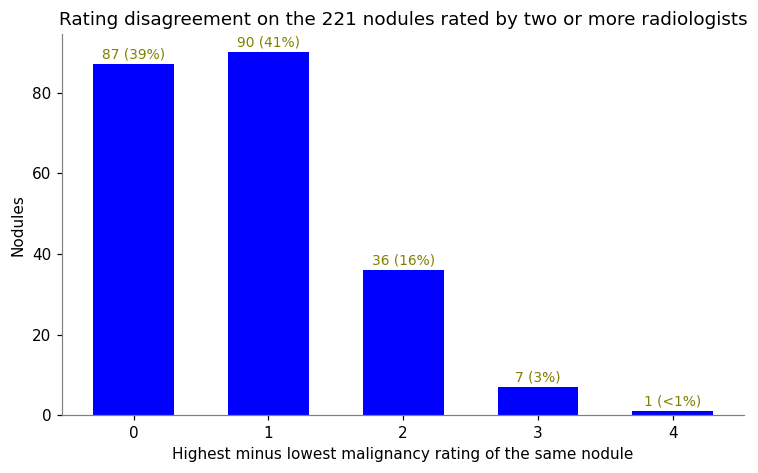

765 rated nodules, 221 rated by more than one radiologist
Range of 2 or more: 44 (20%)
Rated 1 to 2 by one reader and 4 to 5 by another: 21
readers who found it    1    2   3
readers of the scan               
1                     162    0   0
2                     233  112   0
3                     152   65  44
        count  mean
reader             
R1        278  2.25
R2        119  2.09
R3        105  1.57
R4        227  2.72
R5        301  2.18
Ratings of 3: 262, of which 95 by R4


,mean,median,max
label 4 or more,35,35,58
label 2 or less,104,100,81
non integer before rounding,101,78,0


In [12]:
# Ratings of the readings of every nodule
nodule_readings = expanded[expanded["nodule_uid"].isin(lndb.loc[lndb["is_nodule"] == 1, "nodule_uid"])]
per_nodule = (nodule_readings.dropna(subset=["malignancy"])
              .groupby("nodule_uid")["malignancy"].agg(["count", "min", "max", "mean", "median"]))
multi = per_nodule[per_nodule["count"] >= 2].copy()
multi["range"] = (multi["max"] - multi["min"]).astype(int)

counts = multi["range"].value_counts().reindex(range(5), fill_value=0)
fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.bar(counts.index, counts.values, width=0.6, color=BLUE)
for bar, n in zip(bars, counts.values):
    share = f"{n / len(multi):.0%}" if n / len(multi) >= 0.01 else "<1%"
    ax.text(bar.get_x() + bar.get_width() / 2, n + 1.5, f"{n} ({share})", ha="center", fontsize=9, color=OLIVE)
ax.set_xlabel("Highest minus lowest malignancy rating of the same nodule")
ax.set_ylabel("Nodules")
ax.set_title(f"Rating disagreement on the {len(multi)} nodules rated by two or more radiologists")
plt.show()

print(f"{len(per_nodule)} rated nodules, {len(multi)} rated by more than one radiologist")
print(f"Range of 2 or more: {(multi['range'] >= 2).sum()} ({(multi['range'] >= 2).mean():.0%})")
print("Rated 1 to 2 by one reader and 4 to 5 by another:", ((multi["min"] <= 2) & (multi["max"] >= 4)).sum())

# Detection agreement: how many of the scan's readers found each nodule
detection = train_nodules_gt[train_nodules_gt["Nodule"] == 1].merge(train_cts, on="LNDbID")
print(pd.crosstab(detection["RadN"], detection["AgrLevel"], rownames=["readers of the scan"], colnames=["readers who found it"]))

# Reader effect on the ratings
print(nodule_readings.groupby("reader")["malignancy"].agg(["count", "mean"]).round(2))
threes = nodule_readings["malignancy"] == 3
print(f"Ratings of 3: {threes.sum()}, of which {(threes & (nodule_readings['reader'] == 'R4')).sum()} by R4")

# How the aggregation rule changes the label of the multi reader nodules, after rounding half up
half_up = lambda values: np.floor(values + 0.5)
pd.DataFrame({rule: {"label 4 or more": int((half_up(multi[rule]) >= 4).sum()),
                     "label 2 or less": int((half_up(multi[rule]) <= 2).sum()),
                     "non integer before rounding": int((multi[rule] % 1 != 0).sum())}
              for rule in ["mean", "median", "max"]})

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <p>
    Of the 765 rated nodules, only 221 were rated by more than one radiologist, so this histogram describes less than a third of the data. Within those, agreement is reasonable but far from perfect: 87 nodules (39%) got the same rating from everyone and 90 (41%) differ by one point, which on a subjective 1 to 5 scale is close to noise. The remaining 44 (20%) differ by two points or more, and 21 nodules were called benign (1 or 2) by one reader and suspicious (4 or 5) by another.
  </p>
  <p>
    The histogram understates the real disagreement, because it only includes nodules that more than one reader found. In scans read by two radiologists, 233 nodules were found by only one of them and 112 by both; in scans read by three, only 44 of 261 nodules were found by all three. Radiologists disagree more on whether a nodule is there than on how malignant it looks. <strong>'trainNodules_gt.csv'</strong> never merges a nodule call with a non nodule call, so that kind of disagreement cannot be measured from this file. There is also a clear reader effect: R3 has a mean rating of 1.57 and R4 of 2.72, and R4 alone gave 95 of the 262 ratings of 3. Since 71% of the rated nodules have a single reader, their label partly reflects who read the scan, and no aggregation rule can correct that.
  </p>
  <p>
    On aggregation, the choice is less open than it looks. With two readers the median equals the mean, so the two rules differ only on the 44 nodules with three readers, and after rounding half up both give 35 nodules rated 4 or more. The maximum would raise that number to 58. Clinically it is the cautious choice, since one suspicious reading is enough to flag a nodule, but it amplifies reader bias and gives nodules seen by three readers more chances to be labelled suspicious than nodules seen by one, an artefact of the annotation process and not a property of the nodule. The mean is therefore the more defensible default. It gives a non integer value for 101 of the 221 nodules, which is why the rounding rule has to be stated (notebook 00).
  </p>
</div>

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
    Nodule diameter
  </h3>
  <p>
    The diameter is the equivalent diameter of the volume in <strong>'trainNodules_gt.csv'</strong>: the diameter of a sphere with the same volume. Nodules under 3 mm were only marked with a centre and received the volume of a 3 mm sphere, a placeholder that the table above leaves empty.
  </p>
</div>

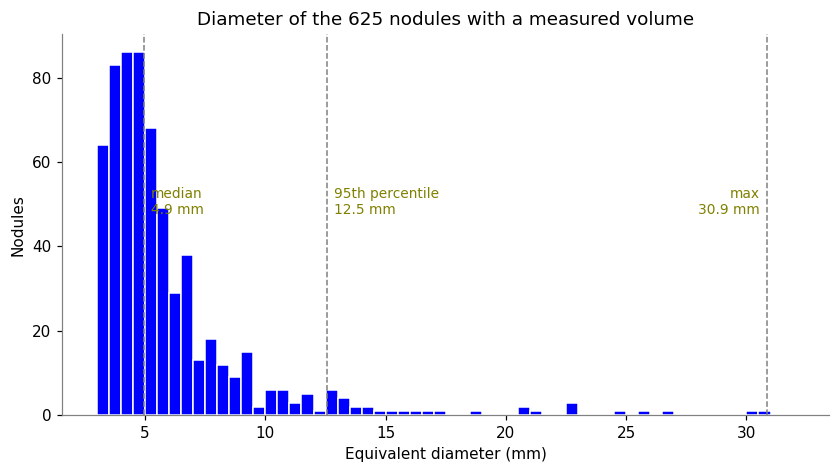

768 nodules: 143 under 3 mm with a placeholder volume, 625 measured
11 nodules above 20 mm


count    625.00
mean       5.99
std        3.50
min        3.04
50%        4.94
90%        9.29
95%       12.54
99%       22.82
max       30.85
Name: diameter_mm, dtype: float64

In [13]:
nodules = lndb[lndb["is_nodule"] == 1]
measured = nodules["diameter_mm"].dropna()          # nodules under 3 mm only have a placeholder volume, left empty
p50, p95, dmax = measured.median(), measured.quantile(0.95), measured.max()

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.hist(measured, bins=np.arange(3, 32.5, 0.5), color=BLUE, edgecolor="white", linewidth=1)
top = ax.get_ylim()[1]
for value, name, align in [(p50, "median", "left"), (p95, "95th percentile", "left"), (dmax, "max", "right")]:
    ax.axvline(value, color=GREY, linestyle="--", linewidth=1)
    offset = 0.3 if align == "left" else -0.3
    ax.text(value + offset, top * 0.6, f"{name}\n{value:.1f} mm", ha=align, va="top", fontsize=9, color=OLIVE)
ax.set_xlabel("Equivalent diameter (mm)")
ax.set_ylabel("Nodules")
ax.set_title(f"Diameter of the {len(measured)} nodules with a measured volume")
plt.show()

print(f"{len(nodules)} nodules: {nodules['volume_is_placeholder'].sum()} under 3 mm with a placeholder volume, {len(measured)} measured")
print(f"{(measured > 20).sum()} nodules above 20 mm")
measured.describe(percentiles=[0.5, 0.9, 0.95, 0.99]).round(2)

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <p>
    Of the 768 nodules, 143 (19%) are under 3 mm and only have the placeholder, so their true size is unknown. They also have no mask, so no feature computed inside a region exists for them. The other 625 have a measured diameter.
  </p>
  <p>
    The measured nodules are small and their distribution is strongly skewed to the right: the median is 4.9 mm, 95% are below 12.5 mm, and only 11 nodules are above 20 mm, with a maximum of 30.9 mm. The smallest measured nodule has 3.04 mm. The 3 mm rule refers to the largest dimension in plane, so a flat or elongated nodule could qualify with a smaller equivalent diameter; seeing none suggests that the threshold was applied to the segmented volume.
  </p>
  <p>
    The cube has to contain the biggest nodules with some margin, because an elongated nodule reaches further than its equivalent diameter along its long axis, and because the Laplacian of Gaussian filters used later need some tissue around the region. We cut a 64 mm cube. Notebook 05 measures it on the regions drawn by the radiologists: a 64 mm cube cuts no region, while a 30 mm cube would cut 10 LNDb and 106 LIDC IDRI regions and the 51 mm cube of extractCube would still cut 4. The features are computed inside the region, so the extra lung around a small nodule does not dilute them.
  </p>
</div>

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
    Voxel spacing across scans
  </h3>
  <p>
    The spacing decides whether and how the scans must be resampled before any feature is computed.
  </p>
</div>

z spacing read from 294 scan headers


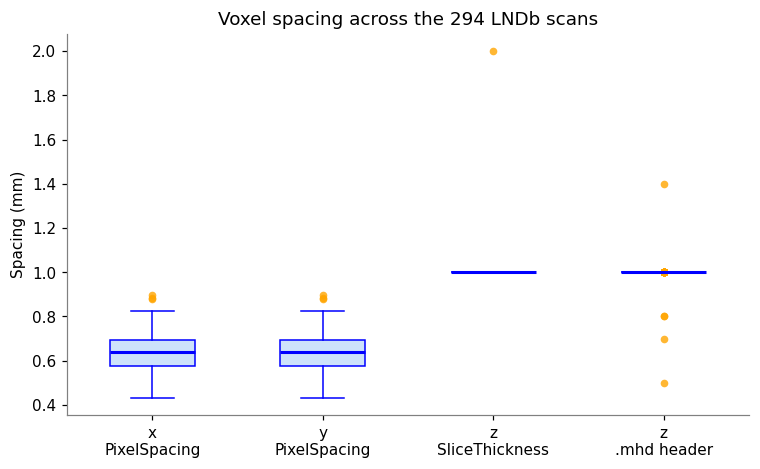

       spacing_x  spacing_y  SliceThickness  spacing_z_header
count    294.000    294.000         294.000           294.000
mean       0.632      0.632           1.003             0.997
std        0.088      0.088           0.058             0.044
min        0.433      0.433           1.000             0.500
25%        0.574      0.575           1.000             1.000
50%        0.640      0.640           1.000             1.000
75%        0.691      0.691           1.000             1.000
max        0.895      0.895           2.000             1.400
Largest x/y difference within a scan: 0.0005 mm
 LNDbID  SliceThickness  spacing_z_header    ManufacturerModelName
    115               1          0.700000 SOMATOM Definition Flash
    209               1          0.500000            SOMATOM go.Up
    268               2          1.400000 SOMATOM Definition Flash
    270               1          0.800062            SOMATOM go.Up
    284               1          0.800000 SOMATOM Definitio

In [14]:
acq = pd.read_csv(find_file("LNDbAcqParams.csv"))
train_cts = pd.read_csv(find_file("trainCTs.csv"))
# In plane spacing comes as the DICOM PixelSpacing string "[row spacing, column spacing]", so [y, x]
pixel_spacing = acq["PixelSpacing"].apply(ast.literal_eval).apply(lambda v: [float(x) for x in v])
acq["spacing_y"] = pixel_spacing.str[0]
acq["spacing_x"] = pixel_spacing.str[1]
# Along z the file only has SliceThickness, which is not the same thing as the distance between slices.
# The actual slice interval is in each .mhd header (ElementSpacing, in x y z order), and reading the header text is enough.
z_header = {}
for mhd_path in Path("../data").rglob("LNDb-*.mhd"):
    scan_id = mhd_path.stem.replace("LNDb-", "")
    if not scan_id.isdigit() or int(scan_id) in z_header: continue # skips masks and duplicate copies of a scan
    for line in mhd_path.read_text().splitlines():
        if line.startswith("ElementSpacing"): z_header[int(scan_id)] = float(line.split("=")[1].split()[2])
acq["spacing_z_header"] = acq["LNDbID"].map(z_header)
print(f"z spacing read from {len(z_header)} scan headers")

columns = ["spacing_x", "spacing_y", "SliceThickness", "spacing_z_header"]
labels = ["x\nPixelSpacing", "y\nPixelSpacing", "z\nSliceThickness", "z\n.mhd header"]

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.boxplot([acq[c].dropna() for c in columns], tick_labels=labels, widths=0.5, patch_artist=True,
           boxprops=dict(facecolor="#cde2fb", edgecolor=BLUE),
           medianprops=dict(color=BLUE, linewidth=2),
           whiskerprops=dict(color=BLUE), capprops=dict(color=BLUE),
           flierprops=dict(marker="o", markersize=5, markerfacecolor=ORANGE, markeredgecolor="none", alpha=0.8))
ax.set_ylabel("Spacing (mm)")
ax.set_title(f"Voxel spacing across the {len(acq)} LNDb scans")
plt.show()

print(acq[columns].describe().round(3))
print("Largest x/y difference within a scan:", (acq["spacing_x"] - acq["spacing_y"]).abs().max().round(4), "mm")

odd_z = acq[~np.isclose(acq["spacing_z_header"], 1.0, atol=0.01)]
print(odd_z[["LNDbID", "SliceThickness", "spacing_z_header", "ManufacturerModelName"]].to_string(index=False))
print("of which in the training set:", odd_z["LNDbID"].isin(train_cts["LNDbID"]).sum())

anisotropy = acq["spacing_z_header"] / acq["spacing_x"]
print(f"z / x spacing ratio: median {anisotropy.median():.2f}, from {anisotropy.min():.2f} to {anisotropy.max():.2f}")
print(acq["ManufacturerModelName"].value_counts().to_string())

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <p>
    <strong>'LNDbAcqParams.csv'</strong> has no <i>SpacingX, SpacingY</i> or <i>SpacingZ</i> columns. The in plane spacing is a single PixelSpacing column holding a two element list stored as text, and along z there is only SliceThickness. Slice thickness and slice spacing are different DICOM quantities, because slices can be reconstructed with overlap, so for z we read ElementSpacing from each .mhd header. That is what utils.readMhd returns and what the rest of the pipeline actually uses.
  </p>
  <p>
    In plane, x and y are the same within each scan (the largest difference is below 0.001 mm), but they vary a lot between scans, from 0.43 mm to 0.89 mm with a median of 0.64 mm. With a fixed 512x512 matrix, the pixel size follows the reconstruction field of view, <strong>which is adjusted to each patient, so this variation is mostly about body size and not different protocols.</strong> 
  </p>
  <p>
    Along z, the picture is the opposite. SliceThickness is 1 mm in 293 of the 294 scans, and the header spacing is 1 mm in 289. The five exceptions (0.5, 0.7, 0.8, 0.8 and 1.4 mm) are all training scans, and only one of them, the 1.4 mm scan reconstructed with 2 mm slices, would be caught by looking at SliceThickness. The other four would go unnoticed if we trusted the CSV, which is a good reason to always take spacing from the image header. All the scans come from three Siemens models, so the acquisition is fairly homogeneous overall.
  </p>
  <p>
    The consequence is that the voxels are anisotropic in practically every scan. The z spacing is typically 1.55 times the in plane spacing and up to 2.3 times, and in the one scan with 0.5 mm slices it goes the other way. <strong>Without resampling, a 6 mm nodule is about 14 pixels wide in one scan and 7 in another</strong>, and texture features that compare neighbouring voxels (GLCM and similar) would be mixing different physical distances depending on direction and on the scan. We must resample to a common isotropic spacing before feature extraction; it is what the IBSI guidelines recommend for 3D radiomics. 
  </p>
  <p>
    The harder question is the target size. The IBSI asks for isotropic voxels but does not fix their size, and its own reference configurations use 2 mm (Zwanenburg et al., 2020). We use 1 mm. Along z it is the real resolution of 289 of the 294 scans, so the grid adds almost no interpolation where the information is coarsest, and it gives the voxel the same physical size in every scan of both datasets. The price is a light loss of resolution in plane, where the median pixel is 0.64 mm. A smaller voxel would keep that detail, but along z it would only interpolate, and LIDC IDRI, with slices of 2 mm in median, would be interpolated even more. Notebook 05 measures these trade offs with a sensitivity analysis at 0.6, 1, 1.5 and 2 mm. Resampling does not solve everything, though. The reconstruction kernel also varies (mostly Br64f and B50f, with some I50f iterative reconstructions), and kernel differences affect texture features at least as much as spacing does. We now have to understand if there is the need to minimise this problem or if it is a limitation to identify.
  </p>
</div>

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
    Malignancy label coverage
  </h3>
  <p>
    Not every nodule has a rating, and not every rated nodule has a mask. Both limit what a malignancy model can use.
  </p>
</div>

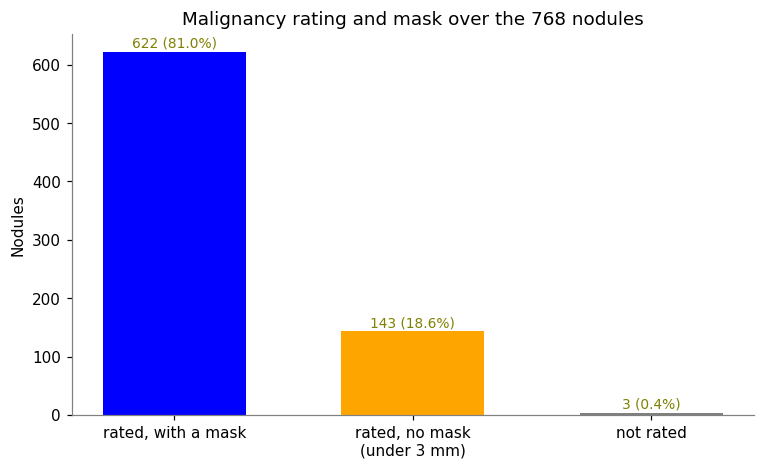

Nodules without a rating: ['LNDb-0085_1', 'LNDb-0121_5', 'LNDb-0122_2']


In [15]:
rated = nodules["mal_mean"].notna()
has_mask = ~nodules["volume_is_placeholder"].astype(bool)
coverage = pd.Series({"rated, with a mask": (rated & has_mask).sum(),
                      "rated, no mask\n(under 3 mm)": (rated & ~has_mask).sum(),
                      "not rated": (~rated).sum()})
assert coverage.sum() == len(nodules)

fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.bar(coverage.index, coverage.values, width=0.6, color=[BLUE, ORANGE, GREY])
for bar, n in zip(bars, coverage.values):
    ax.text(bar.get_x() + bar.get_width() / 2, n + 8, f"{n} ({n / len(nodules):.1%})", ha="center", fontsize=9, color=OLIVE)
ax.set_ylabel("Nodules")
ax.set_title(f"Malignancy rating and mask over the {len(nodules)} nodules")
plt.show()

print("Nodules without a rating:", nodules.loc[~rated, "nodule_uid"].tolist())

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <p>
    Only 3 of the 768 nodules have no rating (in scans 85, 121 and 122), too few to impute, so they are left out. Having a rating does not mean having a mask: 143 rated nodules are the ones under 3 mm, with a centre but no contour. <strong>622 nodules have both a rating and a mask</strong>, and this is the real size of the LNDb labelled set for features computed inside the radiologists' regions.
  </p>
</div>

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
    Malignancy class distribution
  </h3>
  <p>
    The label of each nodule is the mean of its ratings rounded half up, so 2.5 becomes 3 (notebook 00 explains why).
  </p>
</div>

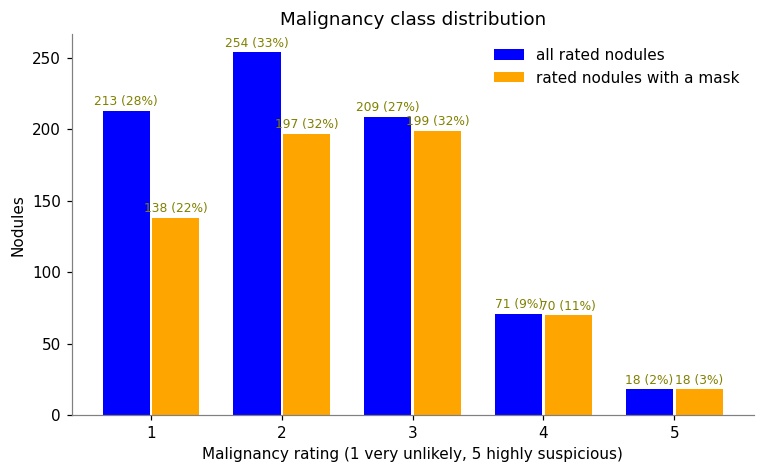

all rated nodules: 1 to 3 scale {1: 467, 2: 209, 3: 89} | most common class 33%
with a mask: 1 to 3 scale {1: 335, 2: 199, 3: 88} | most common class 32%
Ratings of the rated nodules under 3 mm: {1: 75, 2: 57, 3: 10, 4: 1}


,all rated nodules,rated nodules with a mask
rating,,
1,213,138
2,254,197
3,209,199
4,71,70
5,18,18


In [16]:
rated_nodules = nodules[nodules["mal_mean"].notna()].copy()
rated_nodules["rating"] = np.floor(rated_nodules["mal_mean"] + 0.5).astype(int)      # half up: 2.5 becomes 3
with_mask = ~rated_nodules["volume_is_placeholder"].astype(bool)
counts = pd.DataFrame({"all rated nodules": rated_nodules["rating"].value_counts(),
                       "rated nodules with a mask": rated_nodules.loc[with_mask, "rating"].value_counts()}).reindex(range(1, 6)).fillna(0).astype(int)

x, width = np.arange(1, 6), 0.36
fig, ax = plt.subplots(figsize=(8, 4.5))
for offset, column, color in [(-width / 2 - 0.01, "all rated nodules", BLUE), (width / 2 + 0.01, "rated nodules with a mask", ORANGE)]:
    bars = ax.bar(x + offset, counts[column].values, width, color=color, label=column)
    for bar, n in zip(bars, counts[column].values):
        ax.text(bar.get_x() + bar.get_width() / 2, n + 4, f"{n} ({n / counts[column].sum():.0%})", ha="center", fontsize=8, color=OLIVE)
ax.set_xticks(x)
ax.set_xlabel("Malignancy rating (1 very unlikely, 5 highly suspicious)")
ax.set_ylabel("Nodules")
ax.set_title("Malignancy class distribution")
ax.legend(frameon=False)
plt.show()

scale_1_to_3 = lambda rating: np.digitize(rating, [2.5, 3.5]) + 1    # 1 and 2 benign, 3 indeterminate, 4 and 5 suspicious
for name, group in (("all rated nodules", rated_nodules), ("with a mask", rated_nodules[with_mask])):
    three = pd.Series(scale_1_to_3(group["rating"])).value_counts().sort_index()
    print(f"{name}: 1 to 3 scale {three.to_dict()} | most common class {group['rating'].value_counts(normalize=True).max():.0%}")
print("Ratings of the rated nodules under 3 mm:", rated_nodules.loc[~with_mask, "rating"].value_counts().sort_index().to_dict())
counts

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <p>
    The distribution leans clearly towards benign. Of the 765 rated nodules, ratings 1 and 2 are 467 (61%), rating 3 is 209 (27%), and ratings 4 and 5 are only 89 (12%); class 5 has 18 nodules. A model that always predicted the most common class would be right about one time in three while missing every suspicious nodule, so accuracy alone says little.
  </p>
  <p>
    Keeping only the 622 nodules with a mask removes mostly benign ones, because the nodules under 3 mm are almost all rated 1 or 2 (132 of 143). The share of rating 3 rises to 32% and the share of ratings 4 and 5 to 14%, so the imbalance softens but does not go away. The classes are ordered, so a weighted kappa, which penalises predicting 1 for a 5 more than predicting 4 for a 5, describes the errors better than accuracy (Cohen, 1968). Class 3 is also where reader bias is strongest, with R4 giving over a third of the ratings of 3. The folds will be stratified by class and grouped by patient, and the models have to deal with the imbalance (notebook 06).
  </p>
</div>